# Fig. 2 — lattice MC results

Regenerates the two source PDFs behind main Fig. 2 of the droplet paper
(`lattice.tex`, label `lattice-mc-results`; assembled in Inkscape from
`figs/fig2.svg`):

| | | |
|---|---|---|
| `equilibrium_heatmaps_from_20260423.pdf` | (c) top | mean transcription open/closed + P(open) |
| | (b) middle | local concentration heatmap |
| | (a) bottom | probe–enhancer distance heatmap |
| `smooth_local_fisher_rates.pdf` | (d) top | φ_local open/closed with shape fits |
| | (e) bottom | local Fisher rates F_o, F_x, F_local, F_free |

**This notebook reads only `processed_data/` (~68 KB).** The 3.3 GB of raw runs are
not needed. They were reduced once by `prepare_fig2_data.py`, which pooled the
traces across runs and binned the two heatmap observables — the only two ways
Fig. 2 ever consumes them. Everything downstream of that reduction, including
the shape fits and the bootstrap bands of panels (d,e), runs here.

Transcribed from `viz.ipynb`, section "Probe-enhancer transcription". The cell
numbers quoted below are **indices** into that notebook's `cells` array; its
stored execution counts are duplicated throughout and cannot be used to
recover the running order.

## Load the prepared tables

In [ ]:
import os

# This notebook reads processed_data/... relative to figure_production/, so it
# has to run there. Find that directory rather than assume the kernel started
# in it: Jupyter starts in the notebook's folder, VS Code wherever the
# workspace was opened, which may be several levels above or beside it.
DIR_OVERRIDE = None     # set to figure_production's path to skip the search

_SKIP = {"node_modules", "__pycache__", "venv", ".venv", "env", "build", "dist"}


def _ok(d):
    return (os.path.isfile(os.path.join(d, "FIGURE_STYLE.md"))
            and os.path.isdir(os.path.join(d, "processed_data")))


def resolve_figdir():
    if DIR_OVERRIDE:
        if not _ok(DIR_OVERRIDE):
            raise RuntimeError("DIR_OVERRIDE is not figure_production/: " + DIR_OVERRIDE)
        return DIR_OVERRIDE

    # the notebook's own location first -- VS Code exposes it, and it is the
    # one answer that does not depend on where the kernel was started
    starts = []
    nb = globals().get("__vsc_ipynb_file__") or globals().get("__file__")
    if nb:
        starts.append(os.path.dirname(os.path.abspath(nb)))
    starts.append(os.path.abspath(os.getcwd()))

    for start in starts:                      # at or above
        d = start
        for _ in range(6):
            if _ok(d):
                return d
            parent = os.path.dirname(d)
            if parent == d:
                break
            d = parent

    level = [os.path.abspath(os.getcwd())]    # or below, shallowest first
    for _ in range(4):
        nxt = []
        for d in level:
            try:
                names = sorted(os.listdir(d))
            except OSError:
                continue
            for name in names:
                if name.startswith(".") or name in _SKIP:
                    continue
                cand = os.path.join(d, name)
                if not os.path.isdir(cand) or os.path.islink(cand):
                    continue
                if _ok(cand):
                    return cand
                nxt.append(cand)
        level = nxt

    raise RuntimeError(
        "figure_production/ not found from %s -- expected a directory holding "
        "FIGURE_STYLE.md and processed_data/. Set DIR_OVERRIDE above and re-run."
        % os.getcwd())


os.chdir(resolve_figdir())
print("working directory:", os.getcwd())


In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm

DATA = Path("processed_data")       # relative to figure_production/
OUT = Path("figures/fig2")          # where fig2.pdf is written

# float_precision="round_trip" is not optional here. pandas' default CSV float
# parser is not correctly rounded and lands up to one ULP away from the written
# value. That is normally harmless, but the LOOCV behind panel (d) is
# ill-conditioned at the small end of its lambda grid: a perturbation at the
# 1e-16 level there is enough to select a different smoothing weight.
def read(name):
    return pd.read_csv(DATA / name, float_precision="round_trip")


summary = read("fig2_concentration_summary.csv")
hist_conc = read("fig2_hist_local_concentration.csv")
hist_dist = read("fig2_hist_pattern_distance.csv")
boot = read("fig2_transcription_bootstrap.csv")
scalars = json.loads((DATA / "fig2_scalars.json").read_text())

theta = scalars["theta"]                      # volume fraction -> uM  (cell 123)
mean_toff_rnap = scalars["mean_toff_rnap"]    # cell 128
phi_R = scalars["phi_R"]

phi_inf = summary["c_phi"].to_numpy()         # the 16 TF volume fractions
phi_local_closed = summary["phi_local_closed"].to_numpy()
phi_local_open = summary["phi_local_open"].to_numpy()
pclosed = summary["p_closed"].to_numpy()
popen = summary["p_open"].to_numpy()
transcription_closed = summary["transcription_closed"].to_numpy()
transcription_open = summary["transcription_open"].to_numpy()

print("prepared {} from {}".format(scalars["generated_at"], scalars["source_data"]))
print("repo commit {}".format(scalars["repo_commit"]))
summary.head()

prepared 2026-10-07T20:27:26+00:00 from /sessions/rcw-01uurdv6g3nayj1pyvnybegf/mnt/droplet_data/20260423
repo commit 60c48daabed8a23ea5e61f4c8f38ddc7acdffd15


,c_phi,c_uM,phi_local_closed,phi_local_open,p_closed,p_open,transcription_closed,transcription_open,mean_transcription,mean_local_concentration,mean_pattern_distance,n_samples
0,0.003,12.800000,0.005982,0.005976,0.031095,0.968905,0.112795,0.121056,0.120799,0.005976,15.390449,1120219
1,0.004,17.066667,0.008739,0.008470,0.030650,0.969350,0.155123,0.148633,0.148832,0.008478,15.571330,1116412
2,0.005,21.333333,0.011044,0.011357,0.024855,0.975145,0.144255,0.175980,0.175192,0.011349,16.103704,1113940
3,0.006,25.600000,0.085272,0.014833,0.060304,0.939696,0.267748,0.199324,0.203450,0.019081,15.393883,1112333
4,0.007,29.866667,0.137702,0.019964,0.156854,0.843146,0.314494,0.215368,0.230916,0.038432,13.930617,1094051


## Text rendering

`viz.ipynb` cell 132 sets `text.usetex=True`, and in the live session it ran
*before* the heatmap cell — which is why the published heatmap figure also
carries LaTeX serif type. Setting it once here reproduces that for both
figures. It also keeps the long y-labels of panels (a,b,c) from colliding
under `constrained_layout`.

If your LaTeX install is incomplete (`cm-super` / `type1ec.sty` is the usual
missing piece) this falls back to mathtext: the typography will differ from
the published figure, the numbers will not.

In [2]:
def use_latex():
    plt.rcParams.update({"text.usetex": True, "font.family": "serif"})
    try:
        fig = plt.figure()
        fig.text(0.5, 0.5, r"$\phi_{\rm local}$")
        fig.canvas.draw()
        plt.close(fig)
        return True
    except Exception as exc:
        plt.close("all")
        plt.rcParams.update({"text.usetex": False, "font.family": "sans-serif"})
        print("LaTeX unavailable, falling back to mathtext:",
              type(exc).__name__, str(exc).strip()[:120])
        return False

USETEX = use_latex()
print("usetex:", USETEX)

usetex: True


## Smoothing spline

`viz.ipynb` cell 138, helper block only.

$$J[u]=\sum_k \frac{w_k\,(u(x_k)-d_k)^2}{\sum_j w_j}+\lambda\int (u'')^2\,dx$$

One solve, so $y = Hd$ is linear and leave-one-out is exact without refitting:
$e_k=(\hat y_k-d_k)/(1-H_{kk})$. Points carrying no estimate get $w=0$.

Used by panel (c) to smooth the conditional transcription means and their
bootstrap variances.

In [3]:
N_SUB, LOGFIT = 6, True              # N_SUB must match the shape fits below
tr = np.log10 if LOGFIT else (lambda z: z)
inv = (lambda z: 10.0 ** z) if LOGFIT else (lambda z: z)
lams_p = np.logspace(-10, 1, 23)


def fit_smooth(x, d, w, lam, n_sub=N_SUB):
    x, d, w = np.asarray(x, float), np.asarray(d, float), np.asarray(w, float)
    N = d.size
    n = (N - 1) * n_sub + 1
    t = np.linspace(0.0, 1.0, n)
    h = t[1] - t[0]
    idx = np.arange(N) * n_sub
    E2 = (np.eye(n, k=1) * -2 + np.eye(n, k=2) + np.eye(n))[:-2]
    S = np.zeros((N, n))
    S[np.arange(N), idx] = 1.0
    A = S.T @ (w[:, None] * S) / w.sum() + lam * h * (E2.T @ E2) / h ** 4
    A += 1e-12 * np.trace(A) / n * np.eye(n)
    H = np.linalg.solve(A, S.T * w / w.sum())      # y = H d  (cols of w=0 are 0)
    y = H @ np.where(w > 0, d, 0.0)                # so nan endpoints cannot leak
    return dict(x=x[0] + (x[-1] - x[0]) * t, y=y, H=H, idx=idx, lam=lam,
                edf=float(np.trace(H[idx])), w=w,
                valid=(t >= (idx[w > 0][0]) / (n - 1))
                      & (t <= (idx[w > 0][-1]) / (n - 1)))


def loocv_smooth(x, d, w, lams, n_sub=N_SUB):
    """Closed-form leave-one-out over the weighted points only."""
    m = np.asarray(w) > 0
    out = []
    for lam in lams:
        f = fit_smooth(x, d, w, lam, n_sub)
        e = ((f["y"][f["idx"]] - np.where(m, d, 0.0))
             / (1.0 - np.diag(f["H"][f["idx"]])))
        out.append((np.mean(e[m] ** 2), lam, np.where(m, e, 0.0)))
    cv = np.array([o[0] for o in out])
    k = int(np.argmin(cv))
    return out[k][1], cv, out[k][2]

## Panels (a), (b), (c)

`viz.ipynb` cell 163, saved by cell 164.

The one departure from the original: the two heatmaps come from stored
histograms rather than from `np.histogram` over the pooled traces. The stored
matrices are raw `density=True` counts, unsmoothed and unnormalised, so the
gaussian blur along the measurement axis and the per-column normalisation still
happen here and remain adjustable.

The distance axis runs to the 99.5th percentile of the pooled distances. That
cutoff depends on the raw data, so it was frozen at preparation time and is
carried in the stored bin edges.

In [4]:
def hist_matrix(df):
    """(bins x concentrations) densities, plus the full edge vector."""
    edges = np.r_[df["bin_left"].to_numpy(), df["bin_right"].to_numpy()[-1]]
    H = df.drop(columns=["bin_left", "bin_right"]).to_numpy()
    return H, edges


H_conc, ye_c = hist_matrix(hist_conc)
H_dist, ye_d = hist_matrix(hist_dist)

phis = phi_inf
nconc = len(phis)
dx = np.diff(phis).mean()
xe = np.r_[phis * theta - dx / 2, phis[-1] * theta + dx / 2]
xt = (phis + 5e-4) * theta           # same x as the scatter points

boot_closed = boot[boot.state == "closed"].drop(columns=["replicate", "state"]).to_numpy()
boot_open = boot[boot.state == "open"].drop(columns=["replicate", "state"]).to_numpy()


def phi_spline(F, x):
    """Cubic smoothing spline through F(phi), fitted in log10 space at the
    LOOCV lambda."""
    w = (np.isfinite(F) & (F > 0)).astype(float)
    d = tr(np.where(w > 0, F, 1.0))
    lam, _, _ = loocv_smooth(x, d, w, lams_p)
    f = fit_smooth(x, d, w, lam)
    return np.where(w > 0, inv(f["y"][f["idx"]]), np.nan), lam, f["edf"]


transcription_closed_smooth, _, _ = phi_spline(transcription_closed, xt)
transcription_open_smooth, _, _ = phi_spline(transcription_open, xt)
transcription_closed_var = np.nanvar(boot_closed, axis=0, ddof=1)
transcription_open_var = np.nanvar(boot_open, axis=0, ddof=1)
transcription_closed_var_smooth, _, _ = phi_spline(transcription_closed_var, xt)
transcription_open_var_smooth, _, _ = phi_spline(transcription_open_var, xt)

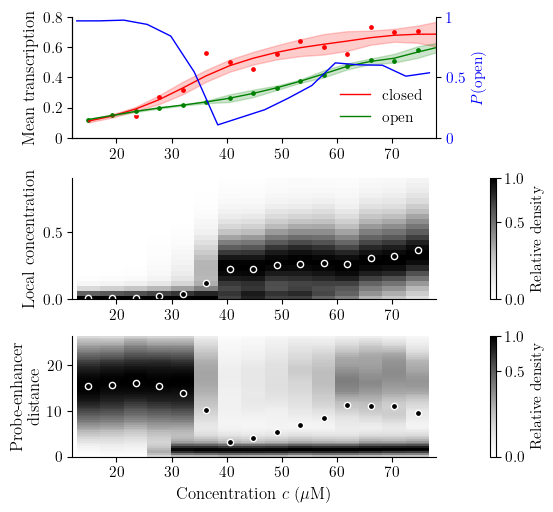

In [5]:
def smooth(H, s):
    """Gaussian blur along the measurement axis (numpy only)."""
    if s <= 0:
        return H
    r = int(np.ceil(3 * s))
    k = np.exp(-0.5 * (np.arange(-r, r + 1) / s) ** 2)
    k /= k.sum()
    return np.apply_along_axis(lambda m: np.convolve(m, k, "same"), 0, H)


def heat(H, ye, ax, gamma=0.5, sig=1.0, cmap="Greys"):
    H = smooth(H, sig)
    Hn = H / (H.max(axis=0, keepdims=True) + 1e-12)      # per-column normalize
    return ax.pcolormesh(xe, ye, Hn, cmap=cmap, norm=PowerNorm(gamma, 0, 1),
                         rasterized=True)


plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})
fig_abc, (a0, a1, a2) = plt.subplots(3, 1, figsize=(5.5, 5), constrained_layout=True)

# ---- panel (c): mean transcription open/closed, with P(open) on the right --
a0.scatter(xt, transcription_closed, color="red", edgecolor="white", s=20)
a0.scatter(xt, transcription_open, color="green", edgecolor="white", s=20)
a0.plot(xt, transcription_closed_smooth, color="red", lw=1, label="closed")
a0.fill_between(xt,
                transcription_closed_smooth - np.sqrt(transcription_closed_var_smooth),
                transcription_closed_smooth + np.sqrt(transcription_closed_var_smooth),
                color="red", alpha=0.2)
a0.plot(xt, transcription_open_smooth, color="green", lw=1, label="open")
a0.fill_between(xt,
                transcription_open_smooth - np.sqrt(transcription_open_var_smooth),
                transcription_open_smooth + np.sqrt(transcription_open_var_smooth),
                color="green", alpha=0.2)
a0.set_ylabel("Mean transcription", fontsize=12, color="black")
a0.set_ylim(0, 0.8)
a0.legend(fontsize=11, loc="lower right", edgecolor="none")
a0.set_yticks([0, 0.2, 0.4, 0.6, 0.8])
a0.set_yticklabels([0, 0.2, 0.4, 0.6, 0.8], color="black")

plt.rcParams.update({"axes.spines.right": True})
a02 = a0.twinx()
a02.plot(phis * theta, popen, color="blue", lw=1)
a02.set_ylabel(r"$P(\rm open)$", color="blue")
a02.set_ylim(0, 1)
a02.set_yticks([0, 0.5, 1])
a02.set_yticklabels([0, 0.5, 1], color="blue")

# ---- panel (b): local concentration, on the k/26 lattice grid --------------
pcm1 = heat(H_conc, ye_c, a1, gamma=0.65, sig=0.8)
fig_abc.colorbar(pcm1, ax=a1, label="Relative density", pad=0.01)
a1.scatter(xt, summary["mean_local_concentration"], color="black",
           edgecolor="white", label="Mean", s=20)
a1.set_ylabel("Local concentration", fontsize=12)
a1.set_ylim(0, 0.9)

# ---- panel (a): probe-enhancer distance -----------------------------------
pcm2 = heat(H_dist, ye_d, a2, gamma=0.5, sig=1.2)
fig_abc.colorbar(pcm2, ax=a2, label="Relative density", pad=0.01)
a2.scatter(xt, summary["mean_pattern_distance"], color="black",
           edgecolor="white", label="Mean", s=20)
a2.set_ylabel("Probe-enhancer \n distance", fontsize=12)
a2.set_xlabel(r"Concentration $c$  $(\mu$M)", fontsize=12)

for a in (a0, a1, a2):
    a.set_xlim(12, 78)

plt.show()

## Shape fit

`viz.ipynb` cell 130.

The unknown is the curve itself, sampled on a refined grid — no functional
form. Shape requirements enter as quadratic-hinge penalties: roughness
($C^1$, in fact $C^2$), monotonically increasing, exactly one inflection whose
position the fit chooses, and a box $lo \le u \le hi$. For a fixed inflection
index the functional is convex and piecewise quadratic, so each iteration is
one small linear solve; active sets and $x^*$ update until they stop changing
(semismooth Newton). $\lambda$ comes from leave-one-out CV, so no shape
parameter is set by hand.

Takes a few seconds — this is the slowest part of the notebook.

In [6]:
def _best_split(q):
    """Cheapest single sign change of q -> (cost, k, orientation).
    orientation=+1: q>=0 for j<k and q<=0 for j>=k (convex then concave)."""
    A = np.maximum(-q, 0.0) ** 2
    B = np.maximum(q, 0.0) ** 2
    cA = np.concatenate(([0.0], np.cumsum(A)))
    cB = np.concatenate(([0.0], np.cumsum(B)))
    cost_p = cA + (cB[-1] - cB)
    cost_m = cB + (cA[-1] - cA)
    kp, km = int(np.argmin(cost_p)), int(np.argmin(cost_m))
    return (cost_p[kp], kp, +1) if cost_p[kp] <= cost_m[km] else (cost_m[km], km, -1)


def fit_shape(x, d, w=None, lam=1e-5, n_sub=6, pen=1e6, n_iter=50, split=None,
              lo=0.0, hi=1.0):
    x, d = np.asarray(x, float), np.asarray(d, float)
    N = d.size
    w = np.ones(N) if w is None else np.asarray(w, float)
    xs, ys = x[-1] - x[0], np.max(np.abs(d))         # normalised units
    n = (N - 1) * n_sub + 1
    t = np.linspace(0.0, 1.0, n)
    h = t[1] - t[0]
    idx = np.arange(N) * n_sub                       # data sit on grid nodes
    v = d / ys
    lb, ub = lo / ys, hi / ys
    E1 = (np.eye(n, k=1) - np.eye(n))[:-1]                          # du
    E2 = (np.eye(n, k=1) * -2 + np.eye(n, k=2) + np.eye(n))[:-2]    # d2u
    S = np.zeros((N, n))
    S[np.arange(N), idx] = 1.0
    A0 = S.T @ (w[:, None] * S) / w.sum() + lam * h * (E2.T @ E2) / h ** 4
    A0 += 1e-12 * np.trace(A0) / n * np.eye(n)
    b0 = S.T @ (w * v) / w.sum()

    u = np.clip(np.interp(t, (x - x[0]) / xs, v), lb, ub)   # start from the data
    k, o, prev = E2.shape[0] // 2, +1, None
    for _ in range(n_iter):
        g, q = E1 @ u, E2 @ u
        if split is None:
            _, k, o = _best_split(q)                 # relocate the inflection
        else:
            k, o = split
        sgn = np.where(np.arange(q.size) < k, o, -o)
        P = (g < 0).astype(float)
        Q = (q * sgn < 0).astype(float)
        L = (u < lb).astype(float)
        U = (u > ub).astype(float)
        A = (A0 + pen * (E1.T @ (P[:, None] * E1)) + pen * (E2.T @ (Q[:, None] * E2))
             + pen * np.diag(L + U))
        b = b0 + pen * (L * lb + U * ub)
        u = np.linalg.solve(A, b)
        key = (P.tobytes(), Q.tobytes(), L.tobytes(), U.tobytes(), k, o)
        if key == prev:
            break
        prev = key

    box_viol = float(np.max(np.maximum(np.maximum(lb - u, u - ub), 0.0)) * ys)
    u = np.clip(u, lb, ub)              # kills the residual O(1/pen) overshoot
    xf, y = x[0] + xs * t, u * ys
    q = (E2 @ u) * ys / (xs * h) ** 2

    H = np.linalg.solve(A, S.T * w / w.sum())        # frozen active set
    G = np.zeros((n, n))                             # np.gradient as a matrix
    dxf = xs * h
    for j in range(n):
        if j == 0:
            G[j, 0:3] = np.array([-3, 4, -1]) / (2 * dxf)
        elif j == n - 1:
            G[j, -3:] = np.array([1, -4, 3]) / (2 * dxf)
        else:
            G[j, j - 1], G[j, j + 1] = -1 / (2 * dxf), 1 / (2 * dxf)

    return dict(x=xf, y=y, dy=G @ y, d2y=q, idx=idx, bounds=(lo, hi),
                lam=lam, orientation=o, x_infl=xf[1:-1][min(k, n - 3)],
                mono_viol=min(np.min(np.diff(y)), 0.0), H=H, G=G,
                edf=float(np.trace(H[idx])), box_viol=box_viol,
                infl_viol=np.max(np.maximum(
                    -q * np.where(np.arange(q.size) < k, o, -o), 0))
                    / np.max(np.abs(q)))


def loocv_lambda(x, d, lams, **kw):
    """Leave-one-out CV for the smoothing weight."""
    cv, loo = [], {}
    for lam in lams:
        e = np.zeros(len(d))
        for k in range(len(d)):
            w = np.ones(len(d))
            w[k] = 0.0
            f = fit_shape(x, d, w=w, lam=lam, **kw)
            e[k] = f["y"][f["idx"][k]] - d[k]
        cv.append(np.mean(e ** 2))
        loo[lam] = e
    cv = np.array(cv)
    lam = lams[int(np.argmin(cv))]
    return lam, cv, loo[lam]


def boot_replicates(x, d, lam, e_loo, nboot=400, seed=0, **kw):
    """Wild bootstrap of the LOO residuals: sign-flip, refit. Sign-flipping
    keeps each point's own noise size, so unequal sampling per concentration is
    fine. Refitting re-chooses the inflection in every replicate, and every
    replicate obeys the box, so the percentile band obeys it for free."""
    rng = np.random.default_rng(seed)
    f = fit_shape(x, d, lam=lam, **kw)
    yhat = f["y"][f["idx"]]
    Y = np.empty((nboot, f["x"].size))
    D = np.empty_like(Y)
    C = np.empty(nboot)
    for b in range(nboot):
        fb = fit_shape(x, yhat + e_loo * rng.choice([-1.0, 1.0], len(d)),
                       lam=lam, **kw)
        Y[b], D[b], C[b] = fb["y"], fb["dy"], fb["x_infl"]
    return Y, D, C

In [7]:
BOX = dict(lo=1e-6, hi=1.0)       # lo>0: phi_local sits in a denominator below
lams = np.logspace(-7, -1, 13)

lam_c, cv_c, eloo_c = loocv_lambda(phi_inf, phi_local_closed, lams, **BOX)
lam_o, cv_o, eloo_o = loocv_lambda(phi_inf, phi_local_open, lams, **BOX)
fit_c = fit_shape(phi_inf, phi_local_closed, lam=lam_c, **BOX)
fit_o = fit_shape(phi_inf, phi_local_open, lam=lam_o, **BOX)

lam_pc, cv_pc, eloo_pc = loocv_lambda(phi_inf, pclosed, lams, **BOX)
lam_po, cv_po, eloo_po = loocv_lambda(phi_inf, popen, lams, **BOX)
# NB the notebook fits pclosed/popen at lam_c/lam_o, not at the lam_pc/lam_po it
# has just computed. Reproduced as-is.
fit_pc = fit_shape(phi_inf, pclosed, lam=lam_c, **BOX)
fit_po = fit_shape(phi_inf, popen, lam=lam_o, **BOX)

Yc, Dc, Cc = boot_replicates(phi_inf, phi_local_closed, lam_c, eloo_c, **BOX)
Yo, Do, Co = boot_replicates(phi_inf, phi_local_open, lam_o, eloo_o, **BOX)

for nm, f, e, C in (("closed", fit_c, eloo_c, Cc), ("open", fit_o, eloo_o, Co)):
    print("{:6s} lam={:.1e} edf={:.1f} sigma_loo={:.4f}  "
          "c*={:.5f} [{:.5f}, {:.5f}]  box_viol={:.2e}".format(
              nm, f["lam"], f["edf"], np.sqrt(np.mean(e ** 2)), f["x_infl"],
              np.percentile(C, 5), np.percentile(C, 95), f["box_viol"]))

closed lam=3.2e-06 edf=6.1 sigma_loo=0.0181  c*=0.00717 [0.00583, 0.00833]  box_viol=0.00e+00
open   lam=3.2e-07 edf=12.8 sigma_loo=0.0040  c*=0.01283 [0.01200, 0.01683]  box_viol=0.00e+00


## Panels (d), (e)

`viz.ipynb` cell 132, saved by cell 133.

The Fisher rate functional is recomputed per bootstrap replicate rather than
propagated, so the band in panel (e) inherits the shape constraints:

$$\dot{\mathcal F}(c)=\frac{\left(\phi'(c)\,c/\phi(c)\right)^2}{1/(k_b\phi)+1/k_u}$$

One wrinkle preserved from the original: the bands below come from the
replicates built in the previous cell with $K_D = 2.3\times10^{-3}$ (cell 128),
while the central curves use $K_D = 2.33\times10^{-3}$ (cell 132). The two
differ by 1.3%. This is what the published panel shows.

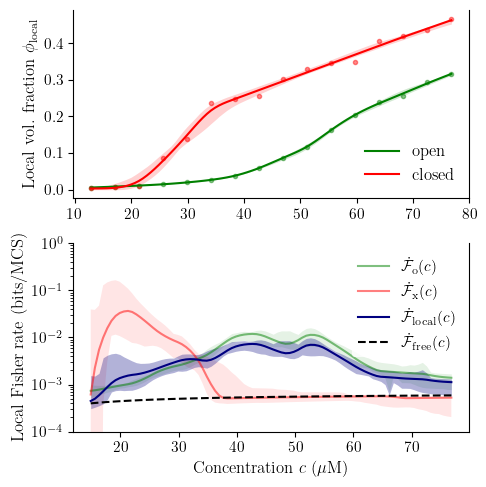

In [8]:
xf = fit_c["x"]                                     # shared refined c-axis
phi_closed_fitted, dphi_closed_fitted = fit_c["y"], fit_c["dy"]
phi_open_fitted, dphi_open_fitted = fit_o["y"], fit_o["dy"]

# --- bands: K_D from cell 128 --------------------------------------------
kb_bands = 1 / (phi_R * mean_toff_rnap)
ku_bands = scalars["K_D_bands"] * kb_bands
popen_i, pclosed_i = (np.interp(xf, phi_inf, popen), np.interp(xf, phi_inf, pclosed))


def fisher_rate(y, dy, kb, ku):
    return (dy * xf / y) ** 2 / (1 / (kb * y) + 1 / ku)


Fc_b = np.array([fisher_rate(Yc[b], Dc[b], kb_bands, ku_bands) for b in range(len(Yc))])
Fo_b = np.array([fisher_rate(Yo[b], Do[b], kb_bands, ku_bands) for b in range(len(Yo))])
qc, qo = (np.percentile(Z, [10, 90], axis=0) for Z in (Fc_b, Fo_b))
band_c = np.percentile(Yc, [10, 90], axis=0)
band_o = np.percentile(Yo, [5, 95], axis=0)

# --- central curves: K_D from cell 132 -----------------------------------
kb = 1 / (phi_R * mean_toff_rnap)
ku = scalars["K_D_curves"] * kb
popen_f, pclosed_f = fit_po["y"], fit_pc["y"]

fisher_rate_open_fit = fisher_rate(phi_open_fitted, dphi_open_fitted, kb, ku)
fisher_rate_closed_fit = fisher_rate(phi_closed_fitted, dphi_closed_fitted, kb, ku)
fisher_rate_base_f = 1 / (1 / (kb * xf) + 1 / ku)
fisher_rate_local_fit = (pclosed_f * fisher_rate_closed_fit
                         + popen_f * fisher_rate_open_fit)

fig_de, ax = plt.subplots(2, 1, figsize=(5, 5))

# ---- panel (d): phi_local open/closed with the shape fits ----------------
ax[0].fill_between(xf * theta, band_c[0], band_c[1], color="red", alpha=0.18, lw=0)
ax[0].fill_between(xf * theta, band_o[0], band_o[1], color="green", alpha=0.18, lw=0)
ax[0].plot(phi_inf * theta, phi_local_open, "o", ms=3, color="green", alpha=0.45)
ax[0].plot(phi_inf * theta, phi_local_closed, "o", ms=3, color="red", alpha=0.45)
ax[0].plot(xf * theta, phi_open_fitted, color="green", label="open")
ax[0].plot(xf * theta, phi_closed_fitted, color="red", label="closed")
ax[0].legend(loc="lower right", edgecolor="none", fontsize=12)
ax[0].set_ylabel(r"Local vol. fraction $\phi_{\rm local}$", fontsize=12)

# ---- panel (e): local Fisher rates ---------------------------------------
ax[1].fill_between(xf[3:] * theta, qc[0][3:], qc[1][3:], color="red", alpha=0.1, lw=0)
ax[1].fill_between(xf[3:] * theta, qo[0][3:], qo[1][3:], color="green", alpha=0.1, lw=0)
ax[1].fill_between(xf[3:] * theta,
                   pclosed_f[3:] * qc[0][3:] + popen_f[3:] * qo[0][3:],
                   pclosed_f[3:] * qc[1][3:] + popen_f[3:] * qo[1][3:],
                   color="navy", alpha=0.3, lw=0)
ax[1].plot(xf[3:] * theta, fisher_rate_open_fit[3:], color="green", alpha=0.5,
           label=r"$\dot{\mathcal{F}}_{\rm o}(c)$")
ax[1].plot(xf[3:] * theta, fisher_rate_closed_fit[3:], color="red", alpha=0.5,
           label=r"$\dot{\mathcal{F}}_{\rm x}(c)$")
ax[1].plot(xf[3:] * theta, fisher_rate_local_fit[3:], color="navy",
           label=r"$\dot{\mathcal{F}}_{\rm local}(c)$")
ax[1].plot(xf[3:] * theta, fisher_rate_base_f[3:], linestyle="dashed", color="black",
           label=r"$\dot{\mathcal{F}}_{\rm free}(c)$")
ax[1].set_yscale("log")
ax[1].legend(edgecolor="none")
ax[1].set_ylim(1e-4, 1)
ax[1].set_xlabel(r"Concentration $c$  $(\mu$M)", fontsize=12)
ax[1].set_ylabel(r"Local Fisher rate (bits/MCS)", fontsize=12)
fig_de.tight_layout()
plt.show()

## Composite figure

Four panels, laid out as

| | |
|---|---|
| A: probe–enhancer distance | C: $\phi_{\rm local}$ open/closed + $P(\rm closed)$ |
| B: local concentration | D: mean transcription open/closed |

**Sized for print.** The paper is `revtex4` twocolumn on A4, where a `figure*`
spans 481.9 pt = 6.69 in, body text is 10 pt and captions are 9 pt. The figure
is therefore built at exactly `FIG_W` inches wide and included at
`width=\linewidth`, so LaTeX applies **no** rescaling and every font below is
the size it will be on the page.

All text is set at the caption size, 9 pt, through `rcParams` rather than
per-call `fontsize=` arguments. Tick labels are the one exception, at 8 pt.
Panel letters are Arial 12 pt — set outside LaTeX, and left larger than the
body text as before.

Because the width is load-bearing, this figure must be saved **without**
`bbox_inches="tight"`: that option re-crops the page to the drawn content, the
PDF stops being 6.69 in wide, and LaTeX silently rescales it again — undoing
the font sizing. `constrained_layout` already trims the margins.

In [ ]:
# ---- font sizes, specified as they will appear on the page ----------------
# The figure keeps its original 11 x 5 in geometry. It is included in a
# figure* at width=\linewidth, and \textwidth = 481.9 pt (measured from
# main.pdf), so LaTeX shrinks it by 481.9/792. Sizes below are therefore
# multiplied by SCALE, and the constants are the printed sizes: 9 pt (the
# caption size) for everything except tick labels at 8 pt.
FIG_W_IN, FIG_H_IN = 11.0, 5.0      # as originally designed -- do not change
TEXTWIDTH_PT = 481.9                # \textwidth of the revtex4 twocolumn page
SCALE = FIG_W_IN * 72 / TEXTWIDTH_PT

PT_CAPTION = 9                      # printed size of labels, legends, colorbars
PT_TICK = 8                         # printed size of tick labels
# Stroke weight in PRINTED points, the same number as in fig3 and fig4 so
# the three figures are one set; multiplied by SCALE like the font sizes,
# because this figure is drawn large and shrunk on inclusion.
LW, LW_AXES = 0.5, 0.5   # printed pt; matches fig3, fig4 and
                         # Tarek's original Fig. 4 (0.50 pt)
PT_LETTER = 12                      # printed size of the Arial panel letters

RC = {
    "font.size": PT_CAPTION * SCALE,
    "axes.labelsize": PT_CAPTION * SCALE,
    "axes.titlesize": PT_CAPTION * SCALE,
    "legend.fontsize": PT_CAPTION * SCALE,
    "xtick.labelsize": PT_TICK * SCALE,
    "ytick.labelsize": PT_TICK * SCALE,
    "lines.linewidth": LW * SCALE,
    "axes.linewidth": LW_AXES * SCALE,
    "xtick.major.width": LW_AXES * SCALE,
    "ytick.major.width": LW_AXES * SCALE,
    # all four spines, as in fig4 and Tarek's originals
    "axes.spines.top": True,
    "axes.spines.right": True,
}
print("figure {:.0f} x {:.0f} pt, included at {:.1f} pt -> scale {:.4f}"
      .format(FIG_W_IN * 72, FIG_H_IN * 72, TEXTWIDTH_PT, 1 / SCALE))
print("labels set at {:.1f} pt in the figure -> {} pt on the page"
      .format(PT_CAPTION * SCALE, PT_CAPTION))


def _renderer(fig):
    """A renderer that works on every matplotlib: get_tightbbox() only made it
    optional in 3.8, and calling it without one raises on 3.5."""
    try:
        return fig.canvas.get_renderer()
    except AttributeError:
        from matplotlib.backends.backend_agg import FigureCanvasAgg
        return FigureCanvasAgg(fig).get_renderer()


# An empty top row reserves space for the A/C letters. The panels fill the
# figure, so without it there is only ~7 pt above the top axes -- not enough
# for a 12 pt (printed) letter, which then runs off the page edge. The figure
# is made taller by exactly the band, so rows 1 and 2 still share the original
# 5 in and the panel aspect ratios are unchanged.
# TRIM compensates: the band row also takes padding, which would otherwise
# leave the panel rows slightly taller and lower the aspect ratio.
BAND_IN, TRIM_IN = 0.30, 0.10

with plt.rc_context(RC):
    # the empty middle column is the gap between left and right panels
    fig_comp = plt.figure(figsize=(FIG_W_IN, FIG_H_IN + BAND_IN - TRIM_IN),
                          layout="constrained")
    gs = fig_comp.add_gridspec(3, 3, width_ratios=[5.5, 0.5, 5],
                               height_ratios=[BAND_IN, FIG_H_IN / 2, FIG_H_IN / 2])
    pA = fig_comp.add_subplot(gs[1, 0])
    pB = fig_comp.add_subplot(gs[2, 0])
    pC = fig_comp.add_subplot(gs[1, 2])
    pD = fig_comp.add_subplot(gs[2, 2])

    # ---- A: probe-enhancer distance (third panel of the a,b,c figure) -----
    pcmA = heat(H_dist, ye_d, pA, gamma=0.5, sig=1.2)
    fig_comp.colorbar(pcmA, ax=pA, label="Relative density", pad=0.01)
    pA.scatter(xt, summary["mean_pattern_distance"], color="black",
               edgecolor="white", s=20)
    pA.set_ylabel("Probe-enhancer \n distance")

    # ---- B: local concentration (second panel of the a,b,c figure) --------
    pcmB = heat(H_conc, ye_c, pB, gamma=0.65, sig=0.8)
    fig_comp.colorbar(pcmB, ax=pB, label="Relative density", pad=0.01)
    pB.scatter(xt, summary["mean_local_concentration"], color="black",
               edgecolor="white", s=20)
    pB.set_ylabel("Local concentration")
    pB.set_ylim(0, 0.9)

    # ---- C: phi_local open/closed with shape fits, P(closed) on the right -
    pC.fill_between(xf * theta, band_c[0], band_c[1], color="red", alpha=0.18, lw=0)
    pC.fill_between(xf * theta, band_o[0], band_o[1], color="green", alpha=0.18, lw=0)
    pC.plot(phi_inf * theta, phi_local_closed, "o", ms=3, color="red", alpha=0.45)
    pC.plot(phi_inf * theta, phi_local_open, "o", ms=3, color="green", alpha=0.45)
    pC.plot(xf * theta, phi_closed_fitted, color="red", label=r"closed, $\phi_{\rm x}$")
    pC.plot(xf * theta, phi_open_fitted, color="green", label=r"open, $\phi_{\rm o}$")
    # top-left corner, pushed hard against the axes and with short handles so
    # the box stays clear of the blue P(closed) curve as it climbs
    pC.legend(loc="upper left", edgecolor="none", framealpha=0.0,
              handlelength=0.9, handletextpad=0.4, borderaxespad=0.15,
              borderpad=0.15, labelspacing=0.25)
    pC.set_ylabel(r"Local vol. fraction $\phi_{\rm local}$")

    pC2 = pC.twinx()
    pC2.plot(phis * theta, pclosed, color="blue", lw=LW * SCALE)
    pC2.set_ylabel(r"$P(\rm closed)$", color="blue")
    pC2.set_ylim(0, 1)
    pC2.set_yticks([0, 0.5, 1])
    pC2.set_yticklabels([0, 0.5, 1], color="blue")
    # RC turns right spines off, and the twin inherits that, so its axis line
    # vanished; switch it back on, blue like its ticks and label
    pC2.spines["right"].set_visible(True)
    pC2.spines["right"].set_color("blue")
    pC2.tick_params(axis="y", colors="blue")

    # ---- D: mean transcription open/closed --------------------------------
    for T, T_s, T_v, col, lab in (
            (transcription_closed, transcription_closed_smooth,
             transcription_closed_var_smooth, "red", "closed"),
            (transcription_open, transcription_open_smooth,
             transcription_open_var_smooth, "green", "open")):
        pD.scatter(xt, T, color=col, edgecolor="white", s=20)
        pD.plot(xt, T_s, color=col, lw=LW * SCALE, label=lab)
        pD.fill_between(xt, T_s - np.sqrt(T_v), T_s + np.sqrt(T_v), color=col, alpha=0.2)
    pD.set_ylabel("Mean transcription")
    pD.set_ylim(0, 0.8)
    pD.set_yticks([0, 0.2, 0.4, 0.6, 0.8])
    pD.legend(loc="lower right", edgecolor="none")

    for a in (pA, pB, pC, pD):
        a.set_xlim(12, 78)
    for a in (pB, pD):
        a.set_xlabel(r"Concentration $c$  $(\mu$M)")

    # ---- panel letters: Arial (so no LaTeX), level with the top of each axes
    # and flush with the leftmost label of its column. Placed in figure
    # coordinates after a layout pass, so they do not perturb the layout.
    fig_comp.canvas.draw()
    rend = _renderer(fig_comp)
    to_fig = fig_comp.transFigure.inverted()
    # The panels fill the figure, so there is only ~7 pt of headroom above the
    # axes -- not enough to hang a letter above them without clipping. They are
    # therefore top-aligned just inside the figure edge, and set one letter-width
    # to the left of the column's leftmost label: panel C's y-label is long
    # enough to reach above its own axes, so a letter at the label's x would sit
    # on top of it.
    LET_DX = 16.0 * SCALE                      # points, in figure units
    for col in ((pA, pB), (pC, pD)):
        x0 = min(to_fig.transform(a.get_tightbbox(rend))[0, 0] for a in col)
        x0 = max(1.0 / (fig_comp.get_size_inches()[0] * 72),
                 x0 - LET_DX / (fig_comp.get_size_inches()[0] * 72))
        for a in col:
            letter = "ABCD"[(pA, pB, pC, pD).index(a)]
            y = a.get_position().y1 + 2.0 * SCALE / (fig_comp.get_size_inches()[1] * 72)
            fig_comp.text(x0, y, letter, usetex=False,
                          fontfamily="Arial", fontsize=PT_LETTER * SCALE,
                          ha="left", va="bottom")

plt.show()

## Save

Written to `media/figures/fig2/`, alongside rather than over the originals in
`media/figures/20260917/`.

In [10]:
OUT.mkdir(parents=True, exist_ok=True)

# Only the composite is saved, and at its true figure size: bbox_inches="tight"
# would re-crop the page and LaTeX would then rescale it, undoing the font
# sizing. fig_abc and fig_de above are working views of the same panels.
path = OUT / "fig2.pdf"
fig_comp.savefig(path, format="pdf")
print("Saved figure to", path)

Saved figure to figures/fig2/fig2.pdf
